# Monthly & Seasonal Patterns


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

cols = ['product_group_name', 'price', 't_dat']

path = '../data/processed/merged_cleaned_2019.csv'

df = pd.read_csv(path,
    usecols=cols, parse_dates=['t_dat']
)

df['month'] = df['t_dat'].dt.month_name()
df.shape

(16396930, 4)

In [31]:
monthly_summary = (df.groupby('month')
              .agg(purchases=('price', 'size'), trading_days=('t_dat', 'nunique'))
              .reindex(month_order))

monthly_summary


,purchases,trading_days
month,,
January,1263471,31
February,1152412,28
March,1286750,31
April,1476454,30
May,1560319,31
June,1906202,30
July,1807494,31
August,1253530,31
September,1227178,30


In [32]:
#monthly revenue per categories 
monthly_rpc = df.pivot_table(
    index='month',
    columns='product_group_name',
    values='price',
    aggfunc='sum'
).reindex(month_order)

monthly_rpc.round(0)

product_group_name,Accessories,Bags,Cosmetic,Furniture,Garment Full body,Garment Lower body,Garment Upper body,Garment and Shoe care,Interior textile,Items,Nightwear,Shoes,Socks & Tights,Swimwear,Underwear,Underwear/nightwear,Unknown
month,,,,,,,,,,,,,,,,,
January,1041.0,2.0,1.0,NaN,2833.0,8701.0,14627.0,NaN,0.0,1.0,468.0,1229.0,336.0,1908.0,2270.0,1.0,34.0
February,995.0,2.0,0.0,NaN,3288.0,8907.0,12813.0,NaN,0.0,1.0,295.0,983.0,324.0,1844.0,1942.0,1.0,32.0
March,991.0,2.0,0.0,NaN,5117.0,10389.0,14170.0,NaN,0.0,1.0,245.0,1315.0,301.0,2919.0,2043.0,1.0,54.0
April,1020.0,1.0,0.0,NaN,8188.0,11634.0,13326.0,NaN,0.0,1.0,282.0,1661.0,290.0,4337.0,2023.0,0.0,61.0
May,1076.0,1.0,0.0,NaN,8293.0,11529.0,12583.0,NaN,0.0,1.0,246.0,1599.0,288.0,5388.0,2311.0,0.0,43.0
June,1028.0,4.0,0.0,NaN,10048.0,12960.0,12495.0,NaN,0.0,1.0,277.0,1611.0,231.0,7380.0,2558.0,0.0,54.0
July,1033.0,9.0,0.0,NaN,7832.0,10843.0,11049.0,NaN,0.0,1.0,255.0,1386.0,211.0,5133.0,2578.0,1.0,55.0
August,906.0,19.0,0.0,NaN,4533.0,8656.0,10987.0,NaN,NaN,2.0,256.0,1187.0,198.0,1483.0,2279.0,0.0,41.0
September,1078.0,20.0,0.0,0.0,4236.0,10605.0,19865.0,0.0,0.0,3.0,367.0,1374.0,326.0,406.0,1988.0,0.0,35.0


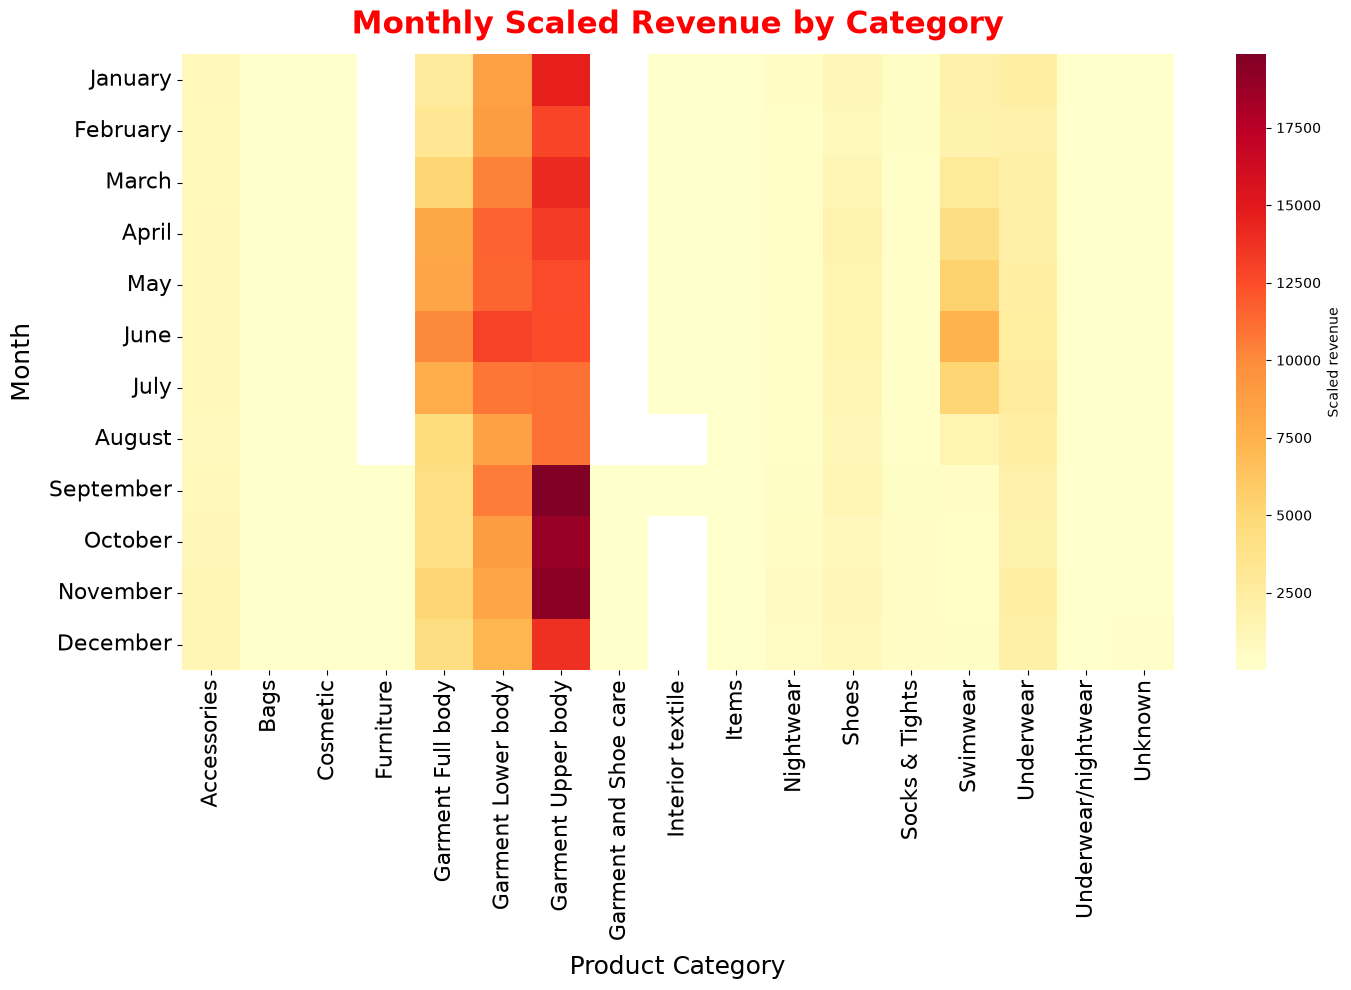

In [33]:
plt.figure(figsize=(16, 8))
sns.heatmap(monthly_rpc, cmap='YlOrRd', annot=False, cbar_kws={'label': 'Scaled revenue'})


plt.title('Monthly Scaled Revenue by Category',fontsize=22,pad=15,fontweight='bold',color='red')

plt.xlabel('Product Category', fontsize=18,labelpad=10)
plt.xticks(fontsize=16)

plt.ylabel('Month',fontsize=18,labelpad=10)
plt.yticks(fontsize=16)

plt.show()

In [34]:
yearly_totals = monthly_rpc.sum(axis=0).sort_values(ascending=False)
share_of_total =yearly_totals/ yearly_totals.sum()


yearly_summary = pd.DataFrame({'scaled_revenue': yearly_totals.round(0), 'share_of_total': share_of_total.map(lambda x:f'{x:.2%}')
})


print(yearly_summary)

                       scaled_revenue share_of_total
product_group_name                                  
Garment Upper body           173905.0         38.17%
Garment Lower body           118623.0         26.04%
Garment Full body             67792.0         14.88%
Swimwear                      31620.0          6.94%
Underwear                     26247.0          5.76%
Shoes                         15631.0          3.43%
Accessories                   12872.0          2.83%
Nightwear                      4386.0          0.96%
Socks & Tights                 3838.0          0.84%
Unknown                         555.0          0.12%
Bags                            104.0          0.02%
Items                            20.0          0.00%
Underwear/nightwear               7.0          0.00%
Furniture                         4.0          0.00%
Cosmetic                          2.0          0.00%
Garment and Shoe care             1.0          0.00%
Interior textile                  0.0         

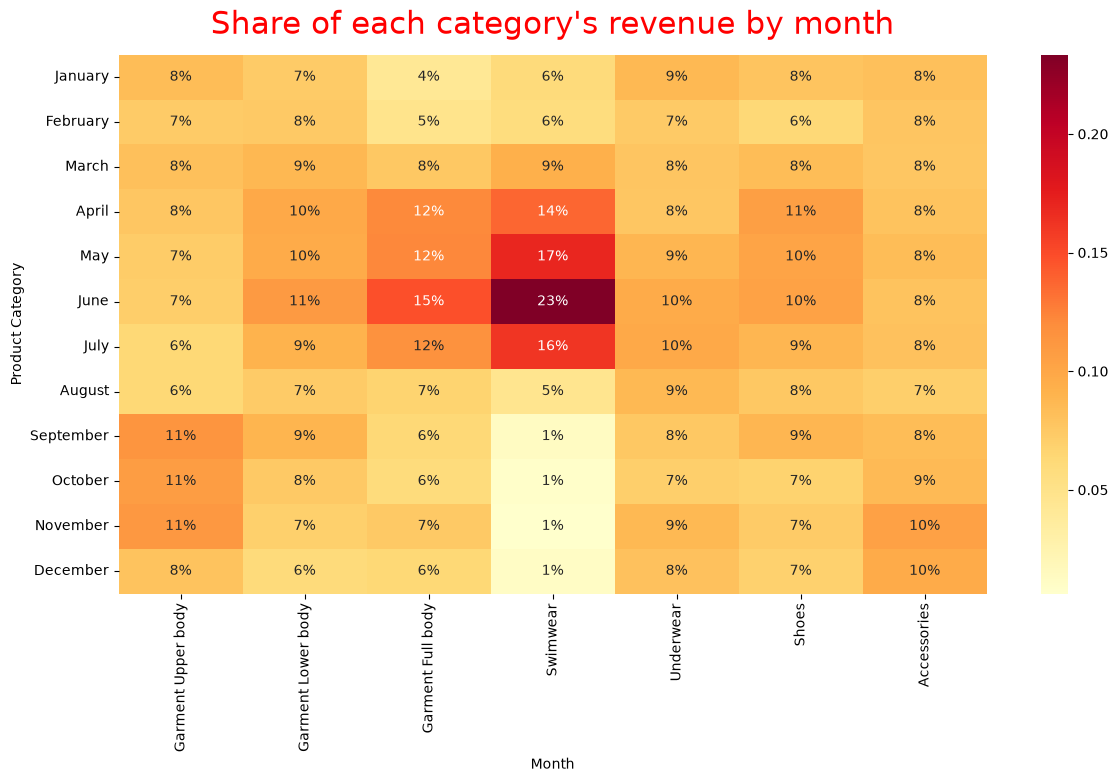

In [35]:
seasonal = monthly_rpc.fillna(0).div(yearly_totals)

major_category = share_of_total[share_of_total >= 0.01].index

plt.figure(figsize=(14, 7))

sns.heatmap(
    seasonal[major_category],
    cmap='YlOrRd',
    annot=True,
    fmt='.0%'
)

plt.title("Share of each category's revenue by month", fontsize=22,color='red',pad=15)
plt.xlabel('Month')
plt.ylabel('Product Category')
plt.show()

In [36]:
monthly_rpc_filled = monthly_rpc.fillna(0)

summary = pd.DataFrame({
    'total_revenue': yearly_totals.round(0),
    'peak_month': seasonal.idxmax(),
    'peak_share': seasonal.max().map(lambda x: f'{x:.1%}'),
    'months_with_sales': monthly_rpc.notna().sum(),
    'variation': (monthly_rpc_filled.std() / monthly_rpc_filled.mean()).round(2),
}).sort_values('total_revenue', ascending=False)

summary

,total_revenue,peak_month,peak_share,months_with_sales,variation
product_group_name,,,,,
Garment Upper body,173905.0,September,11.4%,12,0.22
Garment Lower body,118623.0,June,10.9%,12,0.17
Garment Full body,67792.0,June,14.8%,12,0.41
Swimwear,31620.0,June,23.3%,12,0.91
Underwear,26247.0,July,9.8%,12,0.11
Shoes,15631.0,April,10.6%,12,0.18
Accessories,12872.0,November,10.5%,12,0.11
Nightwear,4386.0,November,15.4%,12,0.39
Socks & Tights,3838.0,November,12.1%,12,0.27


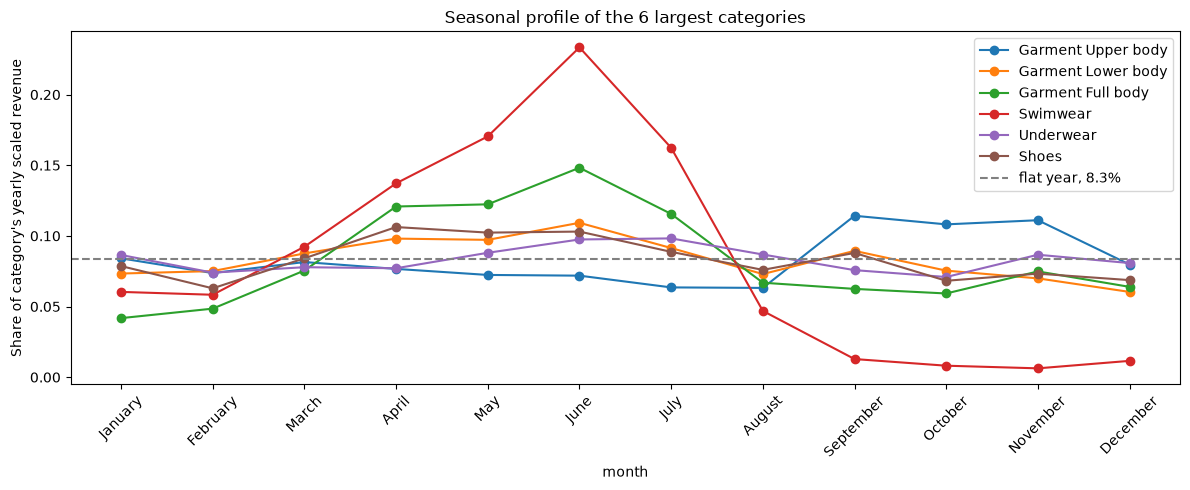

In [37]:
largest_categories = yearly_totals.head(6).index

seasonal[largest_categories].plot(figsize=(12, 5), marker='o')
plt.axhline(1/12, ls='--', c='grey', label='flat year, 8.3%')

plt.xticks(range(12), month_order, rotation=45)

plt.ylabel("Share of category's yearly scaled revenue")

plt.title('Seasonal profile of the 6 largest categories')

plt.legend()
plt.tight_layout()

plt.savefig('../reports/seasonal_profile.png', dpi=150, bbox_inches='tight')
plt.show()

## Findings

A flat category would have 8.3% of its yearly revenue in every month. A higher variation means a more uneven year.

Swimwear is the most seasonal category. June holds 23.3% of its yearly scaled revenue which is about 2.8 times an average month. It stays high in July, then drops sharply in August and sits near 1% from September to December. Its variation is 0.91, the highest of the large categories.

Garment Full body is moderately seasonal. It peaks in June at 14.8%, about 1.8 times an average month, with a variation of 0.41.

Garment Upper body is only mildly seasonal. Its best month is September at 11.4%, about 1.4 times an average month, with a variation of 0.22.

Underwear is flat. Its July peak of 9.8% is barely above 8.3%, with a variation of 0.11.

Furniture, Garment and Shoe care, and Interior textile are not interpreted. They have sales in only 4, 4 and 8 months, and almost no revenue.

Only 2019 is covered and prices are scaled. Months are read as Northern Hemisphere seasons, since the data has no location column. The patterns are consistent with summer for Swimwear.